In [2]:
from pathlib import Path
from datetime import datetime, timezone
from itertools import combinations
import hashlib
import json

import pandas as pd
import yaml
import yfinance as yf

from IPython.display import display


ROOT = Path.cwd().resolve()

if not (ROOT / "configs" / "base.yaml").exists():
    ROOT = ROOT.parent

if not (ROOT / "configs" / "base.yaml").exists():
    raise FileNotFoundError("Open the notebook from the project directory.")

RAW_DIR = ROOT / "data" / "raw" / "development"
RESULTS_DIR = ROOT / "results"

RAW_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(ROOT)

/Users/puppixx1610/Projects/pairs-trading-research


In [3]:
with (ROOT / "configs" / "base.yaml").open() as file:
    config = yaml.safe_load(file)

groups = config["groups"]
tickers = sorted(
    ticker
    for members in groups.values()
    for ticker in members
)

start = config["data"]["start"]
end = config["data"]["end_exclusive"]
interval = config["data"]["interval"]

assert len(tickers) == len(set(tickers)) == 12
assert start == "2010-01-01"
assert end == "2020-01-01"

universe = pd.DataFrame(
    [
        {"group": group, "ticker": ticker}
        for group, members in groups.items()
        for ticker in members
    ]
)

display(universe)

,group,ticker
0,us_large_cap,SPY
1,us_large_cap,IVV
2,us_large_cap,VOO
3,us_total_market,VTI
4,us_total_market,ITOT
5,us_total_market,SCHB
6,developed_ex_us,EFA
7,developed_ex_us,VEA
8,developed_ex_us,SCHF
9,emerging_markets,EEM


In [4]:
settings = {
    "start": start,
    "end": end,
    "interval": interval,
    "auto_adjust": False,
    "actions": True,
    "keepna": True,
    "repair": False,
}

required_columns = {
    "Open", "High", "Low", "Close", "Adj Close", "Volume"
}

for ticker in tickers:
    csv_path = RAW_DIR / f"{ticker}.csv"
    metadata_path = RAW_DIR / f"{ticker}.metadata.json"

    if csv_path.exists():
        if not metadata_path.exists():
            raise FileNotFoundError(f"{ticker}: metadata file is missing.")

        metadata = json.loads(metadata_path.read_text())

        saved_settings = metadata.get("download_settings", metadata)
        saved_end = saved_settings.get(
            "end", saved_settings.get("end_exclusive")
        )

        if (
            saved_settings.get("start") != start
            or saved_end != end
            or saved_settings.get("interval") != interval
            or saved_settings.get("auto_adjust") is not False
        ):
            raise ValueError(f"{ticker}: cached download settings differ.")

        checksum = hashlib.sha256(csv_path.read_bytes()).hexdigest()

        if checksum != metadata.get("sha256"):
            raise ValueError(f"{ticker}: cached file checksum differs.")

        print(f"{ticker}: using saved data")
        continue

    if metadata_path.exists():
        raise FileExistsError(f"{ticker}: metadata exists without a CSV.")

    data = yf.download(
        ticker,
        **settings,
        threads=False,
        progress=False,
        multi_level_index=False,
    )

    if data is None or data.empty:
        raise ValueError(f"{ticker}: download returned no data.")

    missing_columns = required_columns - set(data.columns)

    if missing_columns:
        raise ValueError(f"{ticker}: missing columns {missing_columns}")

    data.to_csv(csv_path, index_label="Date")

    metadata = {
        "ticker": ticker,
        "source": "Yahoo Finance",
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
        "yfinance_version": yf.__version__,
        "download_settings": settings,
        "sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest(),
    }

    metadata_path.write_text(json.dumps(metadata, indent=2))

    print(f"{ticker}: saved {len(data):,} rows")

/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.or

EEM: saved 2,516 rows


/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.or

EFA: saved 2,516 rows


/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.or

...

/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.or

VOO: saved 2,344 rows


/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.or

VTI: saved 2,516 rows
VWO: saved 2,516 rows


/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/puppixx1610/Projects/pairs-trading-research/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.or

In [5]:
raw = {}
coverage_rows = []

for group, members in groups.items():
    for ticker in members:
        data = pd.read_csv(
            RAW_DIR / f"{ticker}.csv",
            index_col="Date",
            parse_dates=True,
        )

        data.index = pd.DatetimeIndex(data.index)

        if data.index.tz is not None:
            data.index = data.index.tz_localize(None)

        data.index = data.index.normalize()

        assert not data.empty, f"{ticker}: empty dataset"
        assert required_columns.issubset(data.columns), ticker
        assert not data.index.hasnans, f"{ticker}: invalid dates"
        assert not data.index.duplicated().any(), ticker
        assert data.index.is_monotonic_increasing, ticker
        assert data.index.min() >= pd.Timestamp(start), ticker
        assert data.index.max() < pd.Timestamp(end), ticker

        valid_prices = data["Adj Close"].dropna()

        assert not valid_prices.empty, f"{ticker}: no adjusted prices"

        raw[ticker] = data

        coverage_rows.append({
            "group": group,
            "ticker": ticker,
            "rows": len(data),
            "valid_prices": len(valid_prices),
            "first_valid": valid_prices.index.min(),
            "last_valid": valid_prices.index.max(),
            "missing_prices": data["Adj Close"].isna().sum(),
            "dividend_data": "Dividends" in data.columns,
            "split_data": "Stock Splits" in data.columns,
        })

coverage = pd.DataFrame(coverage_rows)

coverage.to_csv(
    RESULTS_DIR / "download_coverage_development.csv",
    index=False,
)

display(coverage)

,group,ticker,rows,valid_prices,first_valid,last_valid,missing_prices,dividend_data,split_data
0,us_large_cap,SPY,2516,2516,2010-01-04,2019-12-31,0,True,True
1,us_large_cap,IVV,2516,2516,2010-01-04,2019-12-31,0,True,True
2,us_large_cap,VOO,2344,2344,2010-09-09,2019-12-31,0,True,True
3,us_total_market,VTI,2516,2516,2010-01-04,2019-12-31,0,True,True
4,us_total_market,ITOT,2516,2516,2010-01-04,2019-12-31,0,True,True
5,us_total_market,SCHB,2516,2516,2010-01-04,2019-12-31,0,True,True
6,developed_ex_us,EFA,2516,2516,2010-01-04,2019-12-31,0,True,True
7,developed_ex_us,VEA,2516,2516,2010-01-04,2019-12-31,0,True,True
8,developed_ex_us,SCHF,2516,2516,2010-01-04,2019-12-31,0,True,True
9,emerging_markets,EEM,2516,2516,2010-01-04,2019-12-31,0,True,True


In [6]:
candidate_pairs = pd.DataFrame(
    [
        {"group": group, "A": a, "B": b}
        for group, members in groups.items()
        for a, b in combinations(sorted(members), 2)
    ]
)

assert len(candidate_pairs) == 12

candidate_pairs.to_csv(
    RESULTS_DIR / "candidate_pairs.csv",
    index=False,
)

display(candidate_pairs)

,group,A,B
0,us_large_cap,IVV,SPY
1,us_large_cap,IVV,VOO
2,us_large_cap,SPY,VOO
3,us_total_market,ITOT,SCHB
4,us_total_market,ITOT,VTI
5,us_total_market,SCHB,VTI
6,developed_ex_us,EFA,SCHF
7,developed_ex_us,EFA,VEA
8,developed_ex_us,SCHF,VEA
9,emerging_markets,EEM,IEMG


In [7]:
display(raw["SPY"].head())

display(
    coverage.loc[
        coverage["ticker"].isin(["VOO", "IEMG"]),
        ["ticker", "first_valid", "last_valid", "valid_prices"],
    ]
)

print(f"Loaded {len(raw)} ETFs and defined {len(candidate_pairs)} pairs.")

,Adj Close,Capital Gains,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,,
2010-01-04,84.368996,0.0,113.330002,0.0,113.389999,111.510002,112.370003,0.0,118944600
2010-01-05,84.592285,0.0,113.629997,0.0,113.680000,112.849998,113.260002,0.0,111579900
2010-01-06,84.651871,0.0,113.709999,0.0,113.989998,113.430000,113.519997,0.0,116074400
2010-01-07,85.009201,0.0,114.190002,0.0,114.330002,113.180000,113.500000,0.0,131091100
2010-01-08,85.292084,0.0,114.570000,0.0,114.620003,113.660004,113.889999,0.0,126402800


,ticker,first_valid,last_valid,valid_prices
2,VOO,2010-09-09,2019-12-31,2344
11,IEMG,2012-10-24,2019-12-31,1807


Loaded 12 ETFs and defined 12 pairs.


In [8]:
import numpy as np
import matplotlib.pyplot as plt

raw = {}

for ticker in tickers:
    data = pd.read_csv(
        RAW_DIR / f"{ticker}.csv",
        index_col="Date",
        parse_dates=True,
    )

    data.index = pd.DatetimeIndex(data.index)

    if data.index.tz is not None:
        data.index = data.index.tz_localize(None)

    data.index = data.index.normalize()
    raw[ticker] = data

print(f"Read {len(raw)} datasets from disk.")

Read 12 datasets from disk.


In [9]:
quality_rows = []

for ticker, data in raw.items():
    price = data["Adj Close"]
    volume = data["Volume"]
    valid = price.dropna()

    quality_rows.append({
        "ticker": ticker,
        "rows": len(data),
        "first_valid": valid.index.min(),
        "last_valid": valid.index.max(),
        "valid_prices": price.notna().sum(),
        "duplicate_dates": data.index.duplicated().sum(),
        "dates_sorted": data.index.is_monotonic_increasing,
        "missing_prices": price.isna().sum(),
        "nonpositive_prices": price.le(0).sum(),
        "infinite_prices": np.isinf(price).sum(),
        "missing_volume": volume.isna().sum(),
        "zero_volume": volume.eq(0).sum(),
        "negative_volume": volume.lt(0).sum(),
    })

quality = pd.DataFrame(quality_rows).set_index("ticker")

display(quality)

,rows,first_valid,last_valid,valid_prices,duplicate_dates,dates_sorted,missing_prices,nonpositive_prices,infinite_prices,missing_volume,zero_volume,negative_volume
ticker,,,,,,,,,,,,
EEM,2516,2010-01-04,2019-12-31,2516,0,True,0,0,0,0,0,0
EFA,2516,2010-01-04,2019-12-31,2516,0,True,0,0,0,0,0,0
IEMG,1807,2012-10-24,2019-12-31,1807,0,True,0,0,0,0,0,0
ITOT,2516,2010-01-04,2019-12-31,2516,0,True,0,0,0,0,0,0
IVV,2516,2010-01-04,2019-12-31,2516,0,True,0,0,0,0,0,0
SCHB,2516,2010-01-04,2019-12-31,2516,0,True,0,0,0,0,0,0
SCHF,2516,2010-01-04,2019-12-31,2516,0,True,0,0,0,0,0,0
SPY,2516,2010-01-04,2019-12-31,2516,0,True,0,0,0,0,0,0
VEA,2516,2010-01-04,2019-12-31,2516,0,True,0,0,0,0,0,0


In [10]:
for ticker, data in raw.items():
    observed = data["Adj Close"].dropna()

    assert not data.index.hasnans, f"{ticker}: invalid dates"
    assert not data.index.duplicated().any(), f"{ticker}: duplicate dates"
    assert not observed.empty, f"{ticker}: no valid prices"
    assert np.isfinite(observed).all(), f"{ticker}: infinite prices"
    assert observed.gt(0).all(), f"{ticker}: nonpositive prices"

prices = pd.concat(
    {
        ticker: data["Adj Close"].sort_index()
        for ticker, data in raw.items()
    },
    axis=1,
).sort_index()

prices.index.name = "Date"
prices.columns.name = "ticker"

assert prices.index.min() >= pd.Timestamp(start)
assert prices.index.max() < pd.Timestamp(end)

display(prices.head())
print(prices.shape)

ticker,EEM,EFA,IEMG,ITOT,IVV,SCHB,SCHF,SPY,VEA,VOO,VTI,VWO
Date,,,,,,,,,,,,
2010-01-04,30.194559,34.581207,NaN,18.998682,84.413353,3.375323,8.490403,84.368996,21.372812,NaN,42.853348,27.168003
2010-01-05,30.413719,34.611679,NaN,19.058338,84.658447,3.386658,8.522492,84.592285,21.384987,NaN,43.017845,27.257706
2010-01-06,30.477345,34.757996,NaN,19.084444,84.725273,3.389175,8.535327,84.651871,21.391077,NaN,43.077679,27.424297
2010-01-07,30.300598,34.623890,NaN,19.151566,85.096657,3.400511,8.483987,85.009201,21.348471,NaN,43.257130,27.187220
2010-01-08,30.540976,34.898182,NaN,19.222418,85.386330,3.410586,8.573833,85.292084,21.579727,NaN,43.399216,27.353817


(2516, 12)


In [11]:
gap_rows = []
missing_rows = []

for ticker in tickers:
    price = prices[ticker]

    first = price.first_valid_index()
    last = price.last_valid_index()

    inside = price.loc[first:last]
    missing_dates = inside.index[inside.isna()]

    gap_rows.append({
        "ticker": ticker,
        "first_valid": first,
        "last_valid": last,
        "missing_before_first": price.loc[price.index < first].isna().sum(),
        "missing_inside_history": len(missing_dates),
        "missing_after_last": price.loc[price.index > last].isna().sum(),
    })

    for date in missing_dates:
        missing_rows.append({
            "ticker": ticker,
            "Date": date,
        })

gaps = pd.DataFrame(gap_rows)

missing_dates = pd.DataFrame(
    missing_rows,
    columns=["ticker", "Date"],
)

display(gaps)
display(missing_dates)

,ticker,first_valid,last_valid,missing_before_first,missing_inside_history,missing_after_last
0,EEM,2010-01-04,2019-12-31,0,0,0
1,EFA,2010-01-04,2019-12-31,0,0,0
2,IEMG,2012-10-24,2019-12-31,709,0,0
3,ITOT,2010-01-04,2019-12-31,0,0,0
4,IVV,2010-01-04,2019-12-31,0,0,0
5,SCHB,2010-01-04,2019-12-31,0,0,0
6,SCHF,2010-01-04,2019-12-31,0,0,0
7,SPY,2010-01-04,2019-12-31,0,0,0
8,VEA,2010-01-04,2019-12-31,0,0,0
9,VOO,2010-09-09,2019-12-31,172,0,0


,ticker,Date


In [12]:
returns = prices.pct_change(fill_method=None)

daily_returns = returns.melt(
    ignore_index=False,
    var_name="ticker",
    value_name="daily_return",
).reset_index()

daily_returns = daily_returns.dropna(subset=["daily_return"])
daily_returns["abs_return"] = daily_returns["daily_return"].abs()

return_flags = (
    daily_returns.loc[daily_returns["abs_return"] > 0.10]
    .sort_values("abs_return", ascending=False)
    .reset_index(drop=True)
)

largest_moves = (
    daily_returns.nlargest(10, "abs_return")
    .reset_index(drop=True)
)

print("Moves above 10%:")
display(return_flags)

print("Ten largest moves:")
display(largest_moves)

Moves above 10%:


,Date,ticker,daily_return,abs_return


Ten largest moves:


,Date,ticker,daily_return,abs_return
0,2016-06-24,EFA,-0.085860,0.085860
1,2011-08-08,EEM,-0.083373,0.083373
2,2016-06-24,VEA,-0.081896,0.081896
3,2011-08-08,VWO,-0.080641,0.080641
4,2016-06-24,SCHF,-0.080549,0.080549
5,2011-08-08,VEA,-0.076674,0.076674
6,2011-08-08,EFA,-0.074619,0.074619
7,2011-08-08,SCHF,-0.074374,0.074374
8,2010-05-10,EEM,0.072009,0.072009
9,2011-08-04,VEA,-0.071428,0.071428


In [13]:
def inspect_date(ticker, date, window=3):
    data = raw[ticker].sort_index()
    date = pd.Timestamp(date)

    if date not in data.index:
        raise KeyError(f"{ticker}: date not found")

    position = data.index.get_loc(date)

    columns = [
        "Close",
        "Adj Close",
        "Volume",
        "Dividends",
        "Stock Splits",
        "Capital Gains",
    ]
    columns = [column for column in columns if column in data.columns]

    view = data[columns].copy()
    view["adjusted_return"] = data["Adj Close"].pct_change(fill_method=None)
    view["adjustment_factor"] = data["Adj Close"] / data["Close"]

    return view.iloc[
        max(0, position - window):position + window + 1
    ]


if not largest_moves.empty:
    row = largest_moves.iloc[0]
    print(row["ticker"], row["Date"])
    display(inspect_date(row["ticker"], row["Date"]))

EFA 2016-06-24 00:00:00


,Close,Adj Close,Volume,Dividends,Stock Splits,Capital Gains,adjusted_return,adjustment_factor
Date,,,,,,,,
2016-06-21,58.330002,42.569195,37705500,0.000,0.0,0.0,0.008123,0.729799
2016-06-22,57.119999,42.543110,45176500,1.175,0.0,0.0,-0.000613,0.744802
2016-06-23,58.700001,43.719902,33064500,0.000,0.0,0.0,0.027661,0.744802
2016-06-24,53.660000,39.966106,85314600,0.000,0.0,0.0,-0.085860,0.744803
2016-06-27,52.630001,39.198959,58864400,0.000,0.0,0.0,-0.019195,0.744803
2016-06-28,54.009998,40.226768,45213500,0.000,0.0,0.0,0.026220,0.744802
2016-06-29,55.000000,40.964130,33914900,0.000,0.0,0.0,0.018330,0.744802


In [14]:
row = largest_moves.iloc[1]
display(inspect_date(row["ticker"], row["Date"]))

,Close,Adj Close,Volume,Dividends,Stock Splits,Capital Gains,adjusted_return,adjustment_factor
Date,,,,,,,,
2011-08-03,45.459999,32.948715,73967200,0.0,0.0,0.0,-0.003507,0.724785
2011-08-04,42.860001,31.064272,139352000,0.0,0.0,0.0,-0.057193,0.724785
2011-08-05,42.580002,30.861343,154381700,0.0,0.0,0.0,-0.006533,0.724785
2011-08-08,39.029999,28.288347,175336300,0.0,0.0,0.0,-0.083373,0.724785
2011-08-09,41.320000,29.948107,191406700,0.0,0.0,0.0,0.058673,0.724785
2011-08-10,39.130001,28.360832,122586600,0.0,0.0,0.0,-0.053001,0.724785
2011-08-11,41.290001,29.926373,121153900,0.0,0.0,0.0,0.055201,0.724785


In [15]:
volume_tables = []

for ticker, data in raw.items():
    mask = data["Volume"].isna() | data["Volume"].le(0)

    flagged = data.loc[
        mask,
        ["Close", "Adj Close", "Volume"],
    ].copy()

    flagged.insert(0, "ticker", ticker)
    volume_tables.append(flagged)

volume_flags = pd.concat(volume_tables)
volume_flags.index.name = "Date"
volume_flags = volume_flags.reset_index()

display(volume_flags)

,Date,ticker,Close,Adj Close,Volume


### Observation review

| Ticker | Date | Issue | Evidence checked | Decision |
|---|---|---|---|---|
| EFA | 2016-06-24 | Adjusted close fell 8.59%, the largest absolute daily return in the sample. | Close fell from 58.70 to 53.66. The adjustment factor remained approximately 0.7448. No dividend or split was recorded on the date. A dividend of 1.175 was recorded two sessions earlier, on June 22. | Retain provisionally. The decline appears in both close and adjusted close, with no adjustment-factor discontinuity on the date. Independent price verification remains outstanding. |
| EEM | 2011-08-08 | Adjusted close fell 8.34%, the second-largest absolute daily return in the sample. | Close fell from 42.58 to 39.03. The adjustment factor remained approximately 0.7248. No dividends, splits, or capital gains were recorded in the displayed seven-session window. | Retain provisionally. No corporate-action adjustment anomaly was identified in the displayed data. Independent price verification remains outstanding. |

### Dataset checks

- All 12 ETF datasets have sorted dates and no duplicate dates.
- No missing, nonpositive, or infinite adjusted prices were found within the individual downloaded files.
- No missing, zero, or negative volume observations were found.
- No internal or trailing missing prices were detected against the union of observed ETF dates.
- VOO has 172 missing observations before its first available price on September 9, 2010. IEMG has 709 before October 24, 2012. These leading gaps were left unfilled; first available prices are not assumed to equal fund inception dates.
- No absolute daily returns exceeded 10%. The two largest moves were inspected despite falling below that threshold.
- No observations were removed or prices filled during this review.

### Remaining checks

The other eight observations in the ten-largest-moves table have not
been individually inspected in the saved notebook outputs.

The review checks internal consistency within the downloaded data.
It does not independently confirm historical prices or establish
the economic cause of the large returns. An independent
exchange-calendar audit has not been performed.

In [18]:
formation_sessions = config["strategy"]["formation_sessions"]
pair_rows = []

for group, members in groups.items():
    for a, b in combinations(sorted(members), 2):
        pair = prices[[a, b]].dropna()

        pair_rows.append({
            "group": group,
            "A": a,
            "B": b,
            "common_observations": len(pair),
            "first_common": pair.index.min(),
            "last_common": pair.index.max(),
            "enough_for_formation": len(pair) >= formation_sessions,
            "formation_504th_date": (
                pair.index[formation_sessions - 1]
                if len(pair) >= formation_sessions
                else pd.NaT
            ),
        })

pair_coverage = pd.DataFrame(pair_rows)

assert len(pair_coverage) == 12

display(pair_coverage)

,group,A,B,common_observations,first_common,last_common,enough_for_formation,formation_504th_date
0,us_large_cap,IVV,SPY,2516,2010-01-04,2019-12-31,True,2011-12-30
1,us_large_cap,IVV,VOO,2344,2010-09-09,2019-12-31,True,2012-09-06
2,us_large_cap,SPY,VOO,2344,2010-09-09,2019-12-31,True,2012-09-06
3,us_total_market,ITOT,SCHB,2516,2010-01-04,2019-12-31,True,2011-12-30
4,us_total_market,ITOT,VTI,2516,2010-01-04,2019-12-31,True,2011-12-30
5,us_total_market,SCHB,VTI,2516,2010-01-04,2019-12-31,True,2011-12-30
6,developed_ex_us,EFA,SCHF,2516,2010-01-04,2019-12-31,True,2011-12-30
7,developed_ex_us,EFA,VEA,2516,2010-01-04,2019-12-31,True,2011-12-30
8,developed_ex_us,SCHF,VEA,2516,2010-01-04,2019-12-31,True,2011-12-30
9,emerging_markets,EEM,IEMG,1807,2012-10-24,2019-12-31,True,2014-10-27


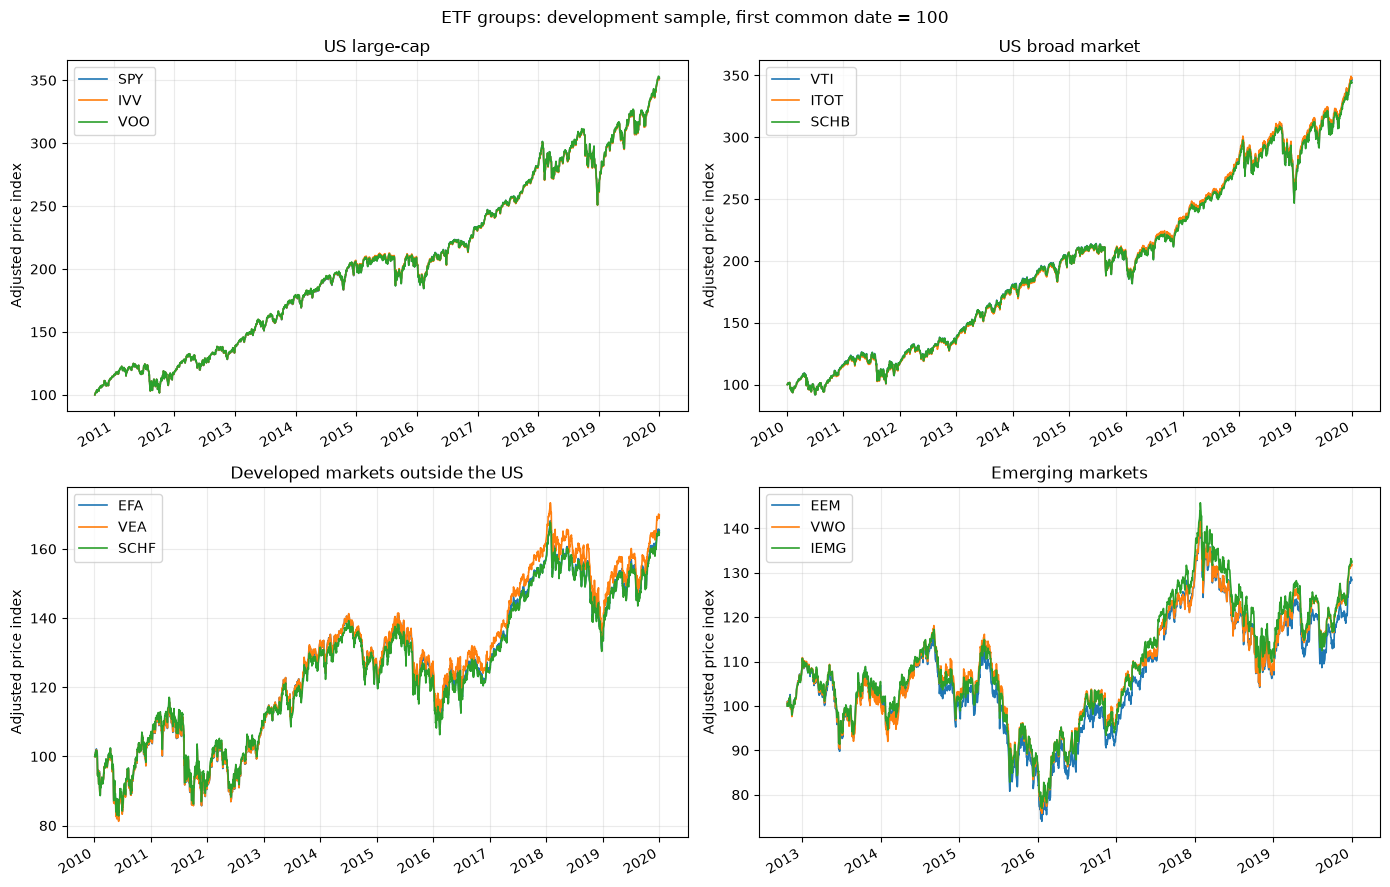

In [19]:
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

group_titles = {
    "us_large_cap": "US large-cap",
    "us_total_market": "US broad market",
    "developed_ex_us": "Developed markets outside the US",
    "emerging_markets": "Emerging markets",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (group, members) in zip(axes.flat, groups.items()):
    common = prices[members].dropna()

    if common.empty:
        ax.set_title(group_titles[group])
        ax.text(0.5, 0.5, "No common observations", ha="center")
        continue

    normalized = common.div(common.iloc[0]).mul(100)

    normalized.plot(ax=ax, linewidth=1.2)

    ax.set_title(group_titles[group])
    ax.set_ylabel("Adjusted price index")
    ax.set_xlabel("")
    ax.grid(alpha=0.25)
    ax.legend(title=None)

fig.suptitle("ETF groups: development sample, first common date = 100")
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "normalized_prices_development.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

In [20]:
group_rows = []

for group, members in groups.items():
    common = prices[members].dropna()

    group_rows.append({
        "group": group,
        "first_common": common.index.min(),
        "last_common": common.index.max(),
        "common_observations": len(common),
    })

group_coverage = pd.DataFrame(group_rows)

display(group_coverage)

,group,first_common,last_common,common_observations
0,us_large_cap,2010-09-09,2019-12-31,2344
1,us_total_market,2010-01-04,2019-12-31,2516
2,developed_ex_us,2010-01-04,2019-12-31,2516
3,emerging_markets,2012-10-24,2019-12-31,1807


### Group observations

#### US large-cap

- **Common sample:** September 9, 2010 to December 31, 2019,
  with 2,344 common observations.
- **Observed similarity or divergence:** SPY, IVV, and VOO overlap
  closely throughout the sample. They share a strong upward trend
  and similar drawdowns, with little separation visible at this scale.
- **Possible explanations to investigate:** Their shared S&P 500
  exposure provides an economic reason for similar movements.
  Small differences may reflect expenses, distributions, tracking,
  or market-price deviations from NAV.
- **What the chart does not establish:** Overlapping normalized
  prices do not establish a stationary spread. Any relative-price
  movement may also be too small to cover trading costs.

#### US broad market

- **Common sample:** January 4, 2010 to December 31, 2019,
  with 2,516 common observations.
- **Observed similarity or divergence:** VTI, ITOT, and SCHB move
  closely together and experience similar turning points. Small
  differences are visible, but none appears to follow a substantially
  different path over the full sample.
- **Possible explanations to investigate:** The funds share broad
  US equity exposure. Differences in index construction, market-cap
  coverage, expenses, and historical benchmark changes may affect
  their relative performance.
- **What the chart does not establish:** Similar long-term performance
  does not demonstrate cointegration or a stable hedge ratio.
  Statistical testing is needed to assess whether deviations persist
  or revert.

#### Developed markets outside the US

- **Common sample:** January 4, 2010 to December 31, 2019,
  with 2,516 common observations.
- **Observed similarity or divergence:** EFA, VEA, and SCHF share
  broadly similar rises and declines, but their paths show more
  visible separation than the US groups. VEA generally sits above
  the other two in parts of the later sample, particularly around
  2017–2018.
- **Possible explanations to investigate:** Differences in country
  coverage, capitalization coverage, and benchmark transitions
  may contribute to the separation. These explanations require
  historical exposure data rather than current fund descriptions alone.
- **What the chart does not establish:** The visible gaps do not
  establish trading opportunities. They could reflect persistent
  differences in exposure rather than temporary mispricing.

#### Emerging markets

- **Common sample:** October 24, 2012 to December 31, 2019,
  with 1,807 common observations.
- **Observed similarity or divergence:** EEM, VWO, and IEMG share
  a decline into early 2016, a recovery toward an early-2018 peak,
  and a subsequent drawdown. Relative performance separates more
  visibly toward the end of the sample, when EEM finishes below
  VWO and IEMG.
- **Possible explanations to investigate:** Country classifications,
  small-cap coverage, China A-share inclusion, expenses, and
  benchmark transitions may affect relative returns.
- **What the chart does not establish:** Shared market cycles do
  not demonstrate a stationary spread. Persistent differences
  between the funds could undermine a mean-reversion strategy.

### Interpretation

Each group is rebased to 100 on its own first common date.
The emerging-market chart therefore covers a shorter period than
the other groups, and ending index levels should not be compared
directly across panels.

These charts motivate pair-level investigation. They do not provide
evidence of cointegration, market neutrality, or profitability after costs.

In [24]:
PROCESSED_DIR = ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

prices.to_parquet(
    PROCESSED_DIR / "adjusted_close_development.parquet",
    engine="pyarrow",
)

quality.to_csv(RESULTS_DIR / "data_quality_summary.csv")

gaps.to_csv(
    RESULTS_DIR / "missing_data_summary.csv",
    index=False,
)

missing_dates.to_csv(
    RESULTS_DIR / "internal_missing_dates.csv",
    index=False,
)

return_flags.to_csv(
    RESULTS_DIR / "return_flags.csv",
    index=False,
)

largest_moves.to_csv(
    RESULTS_DIR / "largest_daily_moves.csv",
    index=False,
)

volume_flags.to_csv(
    RESULTS_DIR / "volume_flags.csv",
    index=False,
)

pair_coverage.to_csv(
    RESULTS_DIR / "pair_coverage.csv",
    index=False,
)

group_coverage.to_csv(
    RESULTS_DIR / "group_coverage.csv",
    index=False,
)

print("Saved processed prices and review tables.")

Saved processed prices and review tables.


In [25]:
saved_prices = pd.read_parquet(
    PROCESSED_DIR / "adjusted_close_development.parquet"
)

pd.testing.assert_frame_equal(prices, saved_prices)

print(
    f"{len(saved_prices):,} dates, "
    f"{saved_prices.shape[1]} ETFs"
)
print(
    f"{saved_prices.index.min().date()} "
    f"to {saved_prices.index.max().date()}"
)

2,516 dates, 12 ETFs
2010-01-04 to 2019-12-31


In [26]:
download_dates = []

for ticker in tickers:
    metadata_path = RAW_DIR / f"{ticker}.metadata.json"
    metadata = json.loads(metadata_path.read_text())
    download_dates.append(metadata["downloaded_at_utc"][:10])

summary = pd.Series({
    "ETFs": len(raw),
    "Candidate pairs": len(pair_coverage),
    "First observed date": prices.index.min().date(),
    "Last observed date": prices.index.max().date(),
    "Duplicate dates": int(quality["duplicate_dates"].sum()),
    "Nonpositive prices": int(quality["nonpositive_prices"].sum()),
    "Infinite prices": int(quality["infinite_prices"].sum()),
    "Internal missing observations": int(
        gaps["missing_inside_history"].sum()
    ),
    "Volume flags": len(volume_flags),
    "Returns above 10% in absolute value": len(return_flags),
    "Pairs with at least 504 observations": int(
        pair_coverage["enough_for_formation"].sum()
    ),
})

print("Download dates:", ", ".join(sorted(set(download_dates))))
display(summary)

Download dates: 2026-10-30


ETFs                                            12
Candidate pairs                                 12
First observed date                     2010-01-04
Last observed date                      2019-12-31
Duplicate dates                                  0
Nonpositive prices                               0
Infinite prices                                  0
Internal missing observations                    0
Volume flags                                     0
Returns above 10% in absolute value              0
Pairs with at least 504 observations            12
dtype: object